# nb05 · L4 动力学与输运

**目的**（`validation_methods_L0-L5.md` L4）：确认结构对了，原子运动是否也对。

每个固定温度液态 state point 输出四样东西：

1. 分物种 MSD；
2. 自扩散系数；
3. **拟合窗口**，以及该窗口内的 log–log 斜率；
4. AIMD 与 MLIP-MD 的 $\log_{10}D$ 差。

参考是 phase-1 canonical 链上的三个液体：950 K（H3 定温段）、1200 K 与 3000 K（H4 熔淬链），
每个 3 条独立副本，所以 $\Delta\log_{10}D$ 可以按副本间涨落正式判级（第 6 节），
三个温度合起来还能看 Arrhenius 行为（第 7 节）。

框架对 L4 有一条硬约束：**升降温轨迹不能伪装成平衡扩散**。这条在代码里是一个守卫函数
`assert_equilibrium_segment`，不是注释——它会先检查协议里的温度是不是一个 (T0, T1) 区间，
再检查轨迹前后半程的温度漂移，任何一条不过就把结果标成 `failed` 并给出理由。

In [1]:
import os
# per-model results/data (results/models/<key>/); without it mlipeval falls back to the
# flat pre-2026-09 layout, which no longer holds current results
os.environ.setdefault("MLIPEVAL_MODEL", "mace_mpa0")
import sys, json
sys.path.insert(0, "../scripts")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mlipeval import datasets, paths
from mlipeval.l4_dynamics import (
    assert_equilibrium_segment, fit_diffusion, max_displacement_per_frame,
    mean_squared_displacement, unwrap,
)
from mlipeval.plotting import species_color, use_style
from mlipeval.state_points import STATES, production_segments, reference_trajectory, states_used_by
from mlipeval.thermo import temperature_series

use_style()
pd.set_option("display.width", 210)
pd.set_option("display.max_colwidth", 70)

## 1. 先证明这个状态点确实是平衡态

第 1–5 节用 `canon_liquid_1200K`（副本 1 ↔ 种子 0）把流程逐步走一遍。守卫要求：
温度序列存在，且前后半程漂移在容差内。

参考: {"name": "aimd_canon_liquid_1200K_r1[500:None:1]", "n_frames": 1500, "n_atoms": 306, "composition": "Ge68Sb68Te170", "volume_A3": 9902.9123, "number_density_at_per_A3": 0.0309, "timestep_fs": 3.0, "sample_stride": 5, "protocol_id": "gst225_aimd_canonical_v1:H4_mq_s01_02_nvt1200", "source": "$MLIPEVAL_WORKSPACE/phase1_vasp_inputs_20260828/H4_mq_s01_02_nvt1200/runs/run_jJ6cPDcHlF/XDATCAR"}
模型: {"name": "mlip_canon_liquid_1200K[500:None:1]", "n_frames": 1501, "n_atoms": 306, "composition": "Ge68Sb68Te170", "volume_A3": 9902.9123, "number_density_at_per_A3": 0.0309, "timestep_fs": 3.0, "sample_stride": 5, "protocol_id": "mlip_md_canon_liquid_1200K_seed0", "source": "$MLIPEVAL_WORKSPACE/eval_framework/data/models/mace_mpa0/md_canon_liquid_1200K__lammps.npz"}


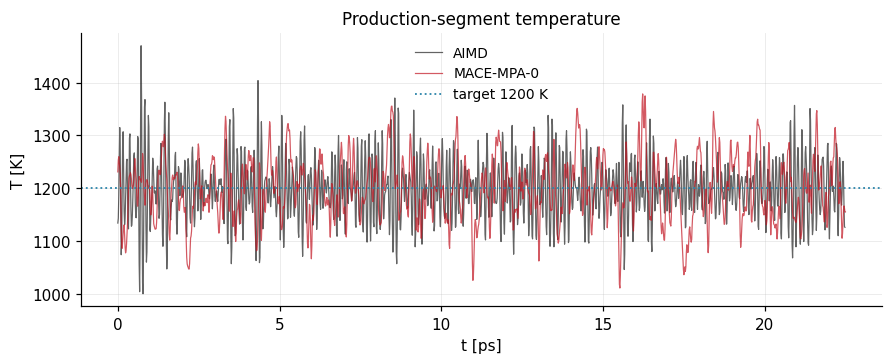

参考: status=ok  value=True  reason=None
       {"mean_T_K": 1199.1986666666667, "std_T_K": 55.85608171800891, "half_to_half_drift_K": 0.15733333333355404}
模型: status=ok  value=True  reason=None
       {"mean_T_K": 1199.1937615589607, "std_T_K": 58.53168907375209, "half_to_half_drift_K": 5.139950766977108}


In [2]:
state = "canon_liquid_1200K"
segments = production_segments(state)
reference, model = segments["reference"], segments["model"]

print("参考:", json.dumps(reference.describe(), ensure_ascii=False))
print("模型:", json.dumps(model.describe(), ensure_ascii=False))

fig, ax = plt.subplots(figsize=(8, 3.2))
for traj, label, color in ((reference, "AIMD", "#222222"), (model, "MACE-MPA-0", "#c1121f")):
    if traj.temperatures is not None:
        ax.plot(traj.frame_time_fs / 1000.0, traj.temperatures, lw=0.8, color=color, alpha=0.7, label=label)
ax.axhline(STATES[state].temperature_k, color="#2e86ab", ls=":", lw=1.2,
           label=f"target {STATES[state].temperature_k:.0f} K")
ax.set_xlabel("t [ps]"); ax.set_ylabel("T [K]"); ax.set_title("Production-segment temperature"); ax.legend()
plt.show()

for traj, label in ((reference, "参考"), (model, "模型")):
    guard = assert_equilibrium_segment(traj)
    print(f"{label}: status={guard.status.value}  value={guard.value}  reason={guard.failure_reason}")
    if guard.extra:
        print("      ", json.dumps(guard.extra, ensure_ascii=False))

### 守卫确实会拒绝变温轨迹

拿同一批数据里的两条变温段来试：淬火（1200 → 300 K）与升温（300 → 1200 K），守卫必须拒绝它们。
这一步是在证明守卫有分辨力，而不是永远返回"通过"。

In [3]:
for name in ("canon_quench", "canon_heating"):
    ramp = reference_trajectory(name)
    guard = assert_equilibrium_segment(ramp)
    print(f"{name:14s} -> {guard.status.value}")
    print(f"{'':14s}    理由: {guard.failure_reason}")

canon_quench   -> failed
                  理由: protocol is a temperature ramp 1200.0 -> 300.0 K; a ramp cannot be used for equilibrium diffusion
canon_heating  -> failed
                  理由: protocol is a temperature ramp 300.0 -> 1200.0 K; a ramp cannot be used for equilibrium diffusion


## 2. 解缠绕（unwrap）与采样安全性

XDATCAR 存的是**包裹**在盒子里的分数坐标，直接算位移会在跨边界处出现整格跳变。
解缠绕对相邻帧取最小镜像位移再累加——但这只有在"任何原子在相邻两帧之间移动不超过半个胞边长"
时才成立。`max_displacement_per_frame` 把这件事量化：返回值 ≥ 1 就说明采样太稀，MSD 不可信。

AIMD         相邻帧最大位移 / 半胞边长 = 0.0249  -> 安全
MACE-MPA-0   相邻帧最大位移 / 半胞边长 = 0.0229  -> 安全


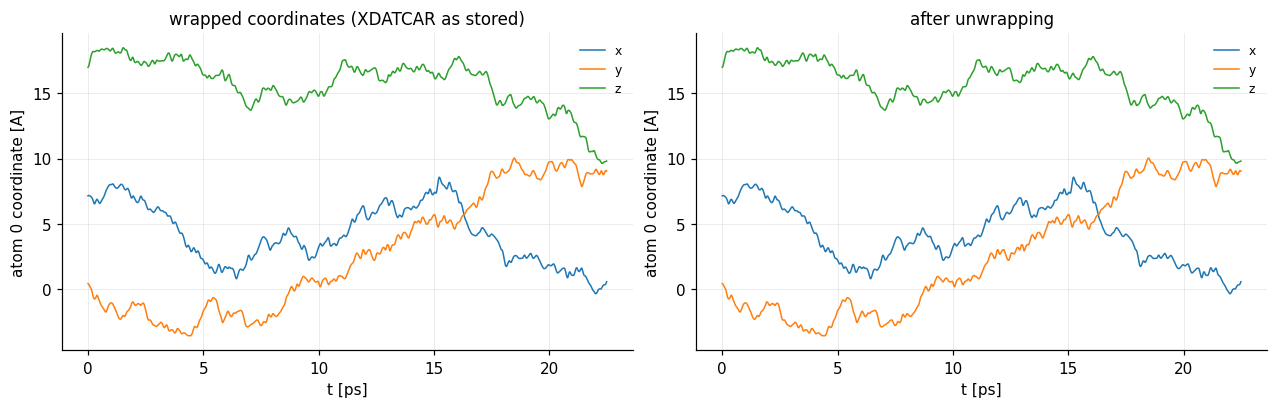

In [4]:
for traj, label in ((reference, "AIMD"), (model, "MACE-MPA-0")):
    ratio = max_displacement_per_frame(traj)
    print(f"{label:12s} 相邻帧最大位移 / 半胞边长 = {ratio:.4f}  -> {'安全' if ratio < 0.5 else '采样过稀'}")

unwrapped = unwrap(reference)
wrapped = reference.positions
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
atom = 0
for ax, (data, title) in zip(axes, [(wrapped, "wrapped coordinates (XDATCAR as stored)"),
                                    (unwrapped, "after unwrapping")]):
    for k, axis in enumerate("xyz"):
        ax.plot(reference.frame_time_fs / 1000.0, data[:, atom, k], lw=1.0, label=axis)
    ax.set_xlabel("t [ps]"); ax.set_ylabel(f"atom {atom} coordinate [A]"); ax.set_title(title); ax.legend(fontsize=8)
plt.show()

## 3. 均方位移

MSD 对**多个时间原点**求平均以压低长滞后端的方差。同时记录每个滞后时间上可用的原点数——
尾部原点数急剧下降的区域不能用来拟合。

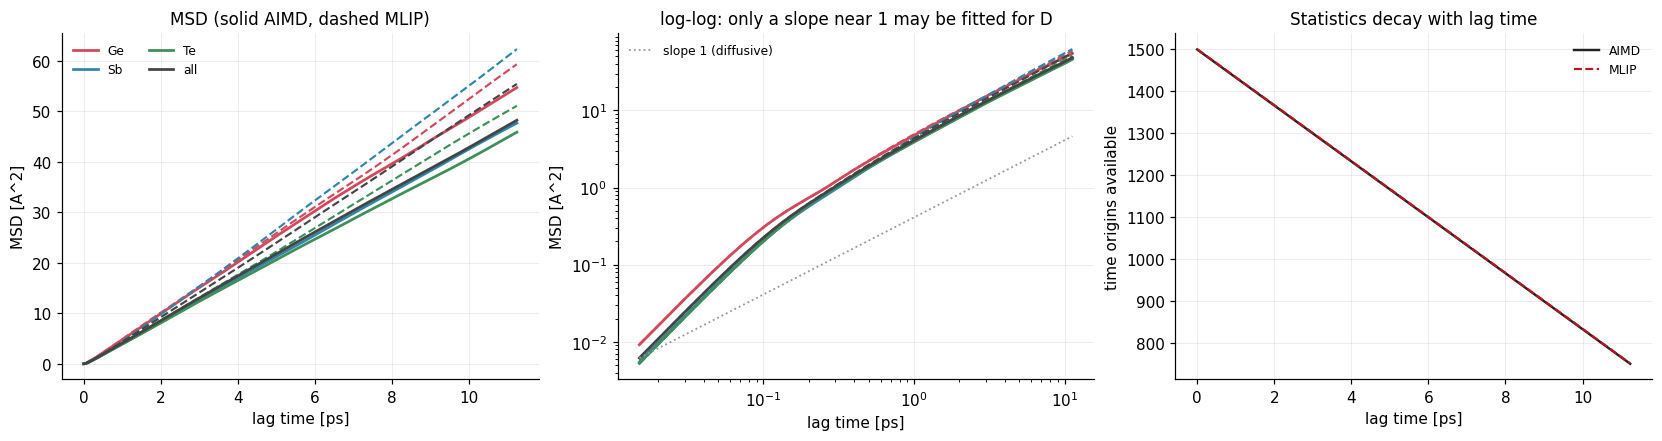

In [5]:
msd_ref = mean_squared_displacement(reference)
msd_model = mean_squared_displacement(model)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
for species in msd_ref.msd:
    color = species_color(species)
    axes[0].plot(msd_ref.time_fs / 1000.0, msd_ref.msd[species], color=color, lw=1.8, label=f"{species}")
    axes[0].plot(msd_model.time_fs / 1000.0, msd_model.msd[species], color=color, lw=1.4, ls="--")
axes[0].set_xlabel("lag time [ps]"); axes[0].set_ylabel("MSD [A^2]")
axes[0].set_title("MSD (solid AIMD, dashed MLIP)"); axes[0].legend(fontsize=8, ncol=2)

for species in msd_ref.msd:
    color = species_color(species)
    axes[1].loglog(msd_ref.time_fs[1:] / 1000.0, msd_ref.msd[species][1:], color=color, lw=1.8)
    axes[1].loglog(msd_model.time_fs[1:] / 1000.0, msd_model.msd[species][1:], color=color, lw=1.4, ls="--")
t = msd_ref.time_fs[1:] / 1000.0
axes[1].loglog(t, msd_ref.msd["all"][1] * (t / t[0]), color="#999", ls=":", lw=1.2, label="slope 1 (diffusive)")
axes[1].set_xlabel("lag time [ps]"); axes[1].set_ylabel("MSD [A^2]")
axes[1].set_title("log-log: only a slope near 1 may be fitted for D"); axes[1].legend(fontsize=8)

axes[2].plot(msd_ref.time_fs / 1000.0, msd_ref.n_origins, color="#222222", lw=1.6, label="AIMD")
axes[2].plot(msd_model.time_fs / 1000.0, msd_model.n_origins, color="#c1121f", lw=1.4, ls="--", label="MLIP")
axes[2].set_xlabel("lag time [ps]"); axes[2].set_ylabel("time origins available")
axes[2].set_title("Statistics decay with lag time"); axes[2].legend(fontsize=8)
plt.show()

## 4. 扩散系数：必须和拟合窗口一起报

$D = \mathrm{MSD}/(6t)$ 只在扩散区成立。同一条 MSD 换一个拟合窗口能给出差好几倍的 $D$，
所以框架明确要求"报告拟合窗口"。这里在**同一个窗口**里同时给出：

- 线性拟合得到的 $D$ 与拟合优度 $R^2$；
- 该窗口的 **log–log 斜率**——只有接近 1 才说明窗口确实落在扩散区；
  否则 `diffusive_regime = False`，metric 直接标 `failed`。

In [6]:
# 两侧轨迹长度不同：拟合窗口必须钉在共同的绝对时间上，
# 否则"同一个分数窗口"会让 AIMD 与 MLIP 落在不同的物理时间范围里。
common_max_fs = min(msd_ref.time_fs[-1], msd_model.time_fs[-1])
print(f"AIMD 最大滞后 {msd_ref.time_fs[-1]/1000:.2f} ps, MLIP {msd_model.time_fs[-1]/1000:.2f} ps"
      f"  -> 共同区间 {common_max_fs/1000:.2f} ps")

windows = [(0.1, 0.5), (0.2, 0.8), (0.4, 0.9)]
rows = []
for lo, hi in windows:
    w_fs = (lo * common_max_fs, hi * common_max_fs)
    for label, msd in (("AIMD", msd_ref), ("MACE-MPA-0", msd_model)):
        fit = fit_diffusion(msd, "all", window_fs=w_fs)
        rows.append({"窗口 (ps)": f"{w_fs[0]/1000:.2f}–{w_fs[1]/1000:.2f}", "来源": label, **fit.to_dict()})
display(pd.DataFrame(rows)[["窗口 (ps)", "来源", "D_cm2_per_s", "loglog_slope", "fit_r2",
                            "fit_window_fs", "diffusive_regime"]].round(6))
print("=> D 对窗口的敏感性正是必须报告窗口的原因。")

AIMD 最大滞后 11.23 ps, MLIP 11.23 ps  -> 共同区间 11.23 ps


,窗口 (ps),来源,D_cm2_per_s,loglog_slope,fit_r2,fit_window_fs,diffusive_regime
0,1.12–5.62,AIMD,0.000074,1.029897,0.999947,"[1125.0, 5610.0]",True
1,1.12–5.62,MACE-MPA-0,0.000082,1.047955,0.999964,"[1125.0, 5610.0]",True
2,2.25–8.99,AIMD,0.000072,0.995801,0.999875,"[2250.0, 8985.0]",True
3,2.25–8.99,MACE-MPA-0,0.000083,1.038941,0.999965,"[2250.0, 8985.0]",True
4,4.49–10.11,AIMD,0.000070,0.975733,0.999914,"[4500.0, 10110.0]",True
5,4.49–10.11,MACE-MPA-0,0.000084,1.037124,0.999978,"[4500.0, 10110.0]",True


=> D 对窗口的敏感性正是必须报告窗口的原因。


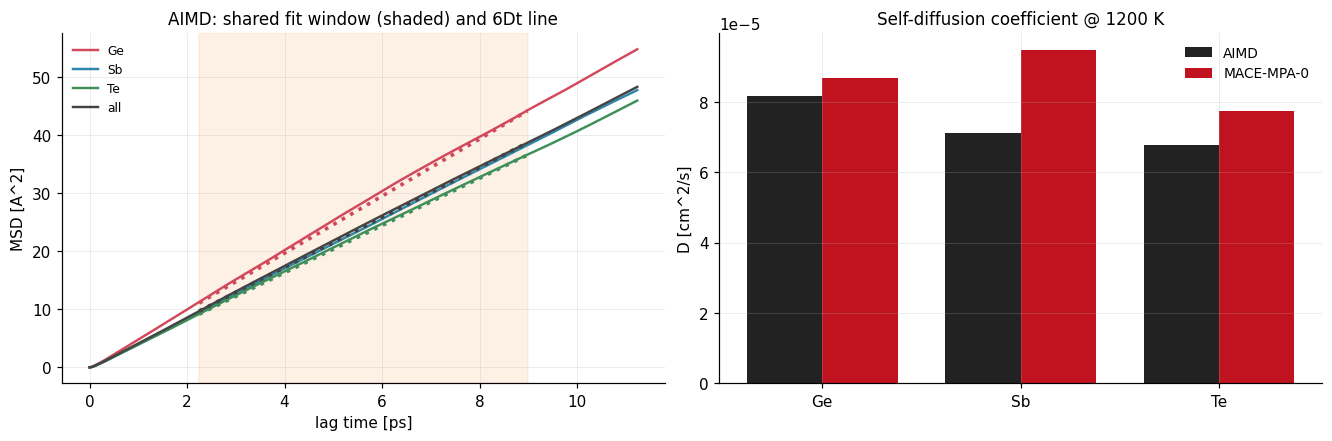

,species,AIMD D (cm^2/s),MLIP D (cm^2/s),Δlog10 D,AIMD 斜率,MLIP 斜率,AIMD 扩散区,MLIP 扩散区
0,Ge,0.00008,0.00009,0.02619,0.98764,1.01180,True,True
1,Sb,0.00007,0.00009,0.12360,1.01153,1.07138,True,True
2,Te,0.00007,0.00008,0.05764,0.99329,1.03614,True,True
3,all,0.00007,0.00008,0.06562,0.99580,1.03894,True,True


In [7]:
window = (0.2, 0.8)
window_fs = (window[0] * common_max_fs, window[1] * common_max_fs)
fits_ref = {s: fit_diffusion(msd_ref, s, window_fs=window_fs) for s in msd_ref.msd}
fits_model = {s: fit_diffusion(msd_model, s, window_fs=window_fs) for s in msd_model.msd}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
for species in msd_ref.msd:
    color = species_color(species)
    axes[0].plot(msd_ref.time_fs / 1000.0, msd_ref.msd[species], color=color, lw=1.6, label=species)
    f = fits_ref[species]
    sel = (msd_ref.time_fs >= f.fit_window_fs[0]) & (msd_ref.time_fs <= f.fit_window_fs[1])
    axes[0].plot(msd_ref.time_fs[sel] / 1000.0, 6 * f.d_A2_per_fs * msd_ref.time_fs[sel],
                 color=color, ls=":", lw=2.4)
axes[0].axvspan(window_fs[0] / 1000.0, window_fs[1] / 1000.0, color="#f2a65a", alpha=0.15)
axes[0].set_xlabel("lag time [ps]"); axes[0].set_ylabel("MSD [A^2]")
axes[0].set_title("AIMD: shared fit window (shaded) and 6Dt line"); axes[0].legend(fontsize=8)

species_list = [s for s in msd_ref.msd if s != "all"]
x = np.arange(len(species_list)); w = 0.38
axes[1].bar(x - w / 2, [fits_ref[s].d_cm2_per_s for s in species_list], w, color="#222222", label="AIMD")
axes[1].bar(x + w / 2, [fits_model[s].d_cm2_per_s for s in species_list], w, color="#c1121f", label="MACE-MPA-0")
axes[1].set_xticks(x); axes[1].set_xticklabels(species_list)
axes[1].set_ylabel("D [cm^2/s]"); axes[1].set_title(f"Self-diffusion coefficient @ {STATES[state].temperature_k:.0f} K")
axes[1].legend()
plt.show()

display(pd.DataFrame([{
    "species": s,
    "AIMD D (cm^2/s)": fits_ref[s].d_cm2_per_s,
    "MLIP D (cm^2/s)": fits_model[s].d_cm2_per_s,
    "Δlog10 D": np.log10(fits_model[s].d_cm2_per_s / fits_ref[s].d_cm2_per_s)
                if fits_ref[s].d_cm2_per_s > 0 and fits_model[s].d_cm2_per_s > 0 else np.nan,
    "AIMD 斜率": fits_ref[s].loglog_slope, "MLIP 斜率": fits_model[s].loglog_slope,
    "AIMD 扩散区": fits_ref[s].diffusive, "MLIP 扩散区": fits_model[s].diffusive,
} for s in msd_ref.msd]).round(5))

## 5. 单对的完整 L4 结果

`analyse_dynamics` 把上面所有步骤串起来并产出 metric。这里只喂了一对轨迹，
所以 `delta_log10D` 仍是 `provisional`；正式判级用三对，见下一节。

In [8]:
from mlipeval.l4_dynamics import analyse_dynamics

report = analyse_dynamics(reference, model_traj=model, window_fraction=window, state_label=state)
frame = report.results.to_frame()
display(frame)
print("状态分布:", frame.status.value_counts().to_dict())

delta = [r for r in report.results if "delta_log10D" in r.metric_id]
for r in delta:
    print(f"\n{r.metric_id}: {r.value:+.4f} decades")
    print("  ", json.dumps(r.extra, ensure_ascii=False))

,metric_id,value,unit,status,tier,grade,z_eff
0,L4.equilibrium_segment@canon_liquid_1200K.reference,True,-,ok,S,ungraded,None
1,L4.equilibrium_segment@canon_liquid_1200K.model,True,-,ok,S,ungraded,None
2,L4.unwrap_safety@canon_liquid_1200K,0.024897,half-cell-edge,ok,S,ungraded,None
3,L4.fit_window@canon_liquid_1200K,<array>,fs,ok,S,ungraded,None
4,L4.diffusion.Ge.D@canon_liquid_1200K,0.000087,cm^2/s,provisional,A,ungraded,None
5,L4.diffusion.Ge.delta_log10D@canon_liquid_1200K,0.026187,decades,provisional,A,ungraded,None
6,L4.diffusion.Sb.D@canon_liquid_1200K,0.000095,cm^2/s,provisional,A,ungraded,None
7,L4.diffusion.Sb.delta_log10D@canon_liquid_1200K,0.123599,decades,provisional,A,ungraded,None
8,L4.diffusion.Te.D@canon_liquid_1200K,0.000077,cm^2/s,provisional,A,ungraded,None
9,L4.diffusion.Te.delta_log10D@canon_liquid_1200K,0.057639,decades,provisional,A,ungraded,None


状态分布: {'provisional': 8, 'ok': 4}

L4.diffusion.Ge.delta_log10D@canon_liquid_1200K: +0.0262 decades
   {"reference_D_cm2_per_s": 8.182898247082898e-05, "model_D_cm2_per_s": 8.691487869751043e-05, "note": "the L4 scoring quantity; requires >= 2 independent references to grade", "grading_note": "provisional: one reference trajectory only, sigma_ref unknown -- no formal grade"}

L4.diffusion.Sb.delta_log10D@canon_liquid_1200K: +0.1236 decades
   {"reference_D_cm2_per_s": 7.133792935024628e-05, "model_D_cm2_per_s": 9.482423468232589e-05, "note": "the L4 scoring quantity; requires >= 2 independent references to grade", "grading_note": "provisional: one reference trajectory only, sigma_ref unknown -- no formal grade"}

L4.diffusion.Te.delta_log10D@canon_liquid_1200K: +0.0576 decades
   {"reference_D_cm2_per_s": 6.776746701940797e-05, "model_D_cm2_per_s": 7.738560583218966e-05, "note": "the L4 scoring quantity; requires >= 2 independent references to grade", "grading_note": "provisional: one 

## 6. 三副本判级

`run_l4.py` 对每个液体状态点做三对配对（种子 k ↔ 副本 k+1），并用三对"副本 vs 副本"的
$\Delta\log_{10}D$ 的 RMS 作为 `sigma_ref`——也就是两条独立 AIMD 链之间的扩散系数本来就会差多少
（有限长度、有限原子数下的统计误差）。

,state,T (K),species,D_AIMD (cm^2/s),D_MLIP (cm^2/s),Δlog10 D,sigma_ref,z_eff,grade,per-pair Δ
0,canon_liquid_1200K,1200.0,Ge,0.00008,0.00009,-0.00481,0.04859,0.09905,A,"[0.026, -0.074, 0.033]"
1,canon_liquid_1200K,1200.0,Sb,0.00007,0.00009,0.09198,0.01497,6.14542,F,"[0.124, 0.081, 0.071]"
2,canon_liquid_1200K,1200.0,Te,0.00007,0.00008,0.03852,0.05747,0.67016,A,"[0.058, 0.047, 0.011]"
3,canon_liquid_1200K,1200.0,all,0.00007,0.00008,0.03993,0.03175,1.25774,B,"[0.066, 0.025, 0.029]"
4,canon_liquid_950K,950.0,Ge,0.00004,0.00007,0.10554,0.03873,2.72538,C,"[0.183, 0.086, 0.047]"
5,canon_liquid_950K,950.0,Sb,0.00004,0.00006,0.13734,0.07612,1.80420,B,"[0.199, 0.051, 0.162]"
6,canon_liquid_950K,950.0,Te,0.00003,0.00005,0.11684,0.02126,5.49600,F,"[0.154, 0.062, 0.134]"
7,canon_liquid_950K,950.0,all,0.00004,0.00006,0.11864,0.03153,3.76278,C,"[0.172, 0.065, 0.119]"
8,canon_liquid_3000K,3000.0,Ge,0.00026,0.00027,-0.01328,0.06247,0.21257,A,"[0.006, -0.042, -0.004]"
9,canon_liquid_3000K,3000.0,Sb,0.00024,0.00025,-0.00345,0.04831,0.07149,A,"[0.022, -0.047, 0.015]"


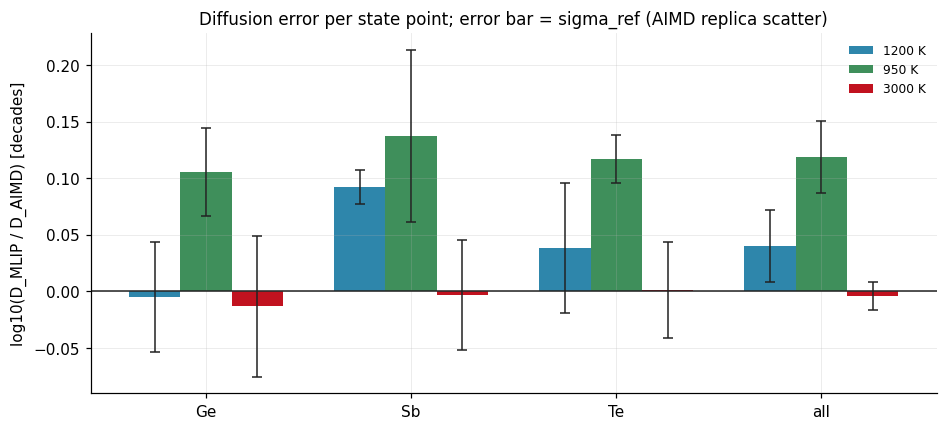

In [9]:
L4_STATES = states_used_by("L4")
rows = []
for name in L4_STATES:
    path = paths.result_path(f"L4_{name}__lammps.json")
    if not path.exists():
        continue
    for r in json.loads(path.read_text())["results"]:
        if ".delta_log10D@" not in r["metric_id"]:
            continue
        sp = r["metric_id"].split(".")[2]
        rows.append({"state": name, "T (K)": STATES[name].temperature_k, "species": sp,
                     "D_AIMD (cm^2/s)": r["extra"]["reference_D_cm2_per_s"],
                     "D_MLIP (cm^2/s)": r["extra"]["model_D_cm2_per_s"],
                     "Δlog10 D": r["value"], "sigma_ref": r["uncertainty"],
                     "z_eff": r["z_eff"], "grade": r["grade"],
                     "per-pair Δ": [round(p["value"], 3) for p in r["extra"]["per_replica"]]})
l4 = pd.DataFrame(rows)
display(l4.round(5))

fig, ax = plt.subplots(figsize=(8.5, 3.8))
species = ["Ge", "Sb", "Te", "all"]
w = 0.25
for j, name in enumerate(L4_STATES):
    sub = l4[l4.state == name].set_index("species").reindex(species)
    x = np.arange(len(species)) + (j - 1) * w
    ax.bar(x, sub["Δlog10 D"], width=w, label=f"{STATES[name].temperature_k:.0f} K",
           color=["#2e86ab", "#3f8f5b", "#c1121f"][j % 3])
    ax.errorbar(x, sub["Δlog10 D"], yerr=sub["sigma_ref"], fmt="none", ecolor="#222", capsize=3, lw=1)
ax.axhline(0, color="#222", lw=1.0)
ax.set_xticks(np.arange(len(species))); ax.set_xticklabels(species)
ax.set_ylabel("log10(D_MLIP / D_AIMD) [decades]")
ax.set_title("Diffusion error per state point; error bar = sigma_ref (AIMD replica scatter)")
ax.legend(fontsize=8)
plt.show()

## 7. 三个温度合起来：Arrhenius

单个温度上的 $\Delta\log_{10}D$ 可能互相抵消地对或错；把三个温度放在同一张 $\log D$–$1/T$ 图上，
才能看出模型的**激活能**是否正确——这决定了它外推到别的温度时会不会系统性跑偏。
3000 K 远高于 GST225 的熔点（约 900 K），只当作高温锚点。

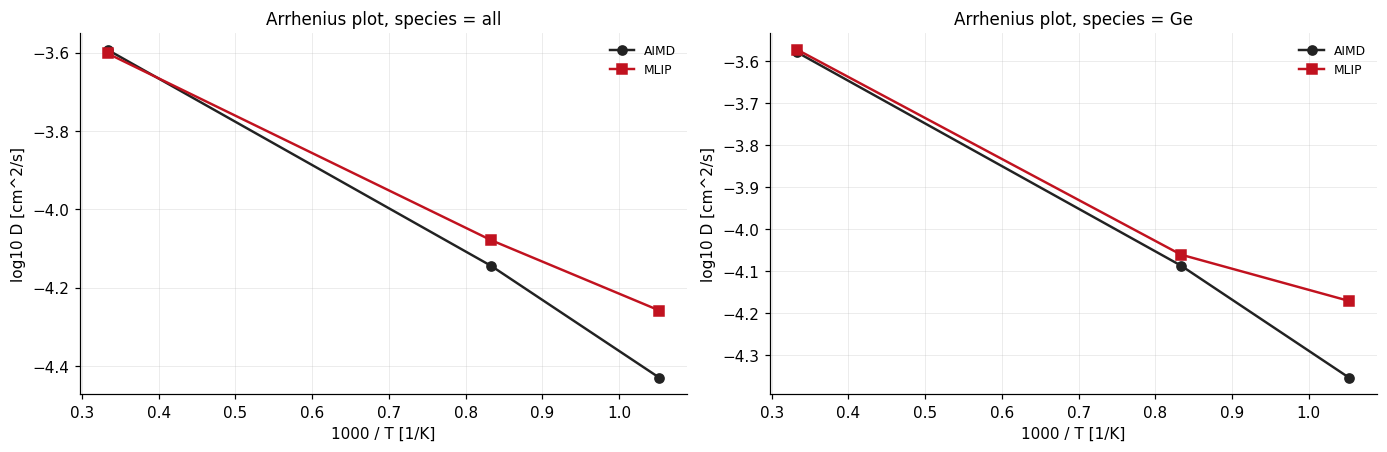

,species,source,"E_a (eV), 950-1200 K"
0,all,AIMD,0.2585
1,all,MLIP,0.1625
2,Ge,AIMD,0.2422
3,Ge,MLIP,0.1001


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0))
kB = 8.617333e-5  # eV/K
fits = []
for sp, ax in zip(("all", "Ge"), axes):
    sub = l4[l4.species == sp].sort_values("T (K)")
    inv_t = 1000.0 / sub["T (K)"].values
    for col, label, color, mk in (("D_AIMD (cm^2/s)", "AIMD", "#222222", "o"),
                                  ("D_MLIP (cm^2/s)", "MLIP", "#c1121f", "s")):
        y = np.log10(sub[col].values)
        ax.plot(inv_t, y, mk + "-", color=color, label=label, ms=6)
        liquid = sub["T (K)"].values < 2000          # activation energy from 950 and 1200 K only
        if liquid.sum() >= 2:
            slope = np.polyfit(1.0 / sub["T (K)"].values[liquid], np.log(sub[col].values[liquid]), 1)[0]
            fits.append({"species": sp, "source": label, "E_a (eV), 950-1200 K": -slope * kB})
    ax.set_xlabel("1000 / T [1/K]"); ax.set_ylabel("log10 D [cm^2/s]")
    ax.set_title(f"Arrhenius plot, species = {sp}")
    ax.legend(fontsize=8)
plt.show()
display(pd.DataFrame(fits).round(4))

## 小结

（执行后填写。）